In [4]:
import numpy as np
import matplotlib.pyplot as plt

N_STATES = 10
START_STATE = N_STATES // 2

LEFT_TERMINAL_REWARD = -1
RIGHT_TERMINAL_REWARD = 1
STEP_REWARD = 0

ACTION_LEFT = -1
ACTION_RIGHT = 1
ACTIONS = [ACTION_LEFT, ACTION_RIGHT]

def take_step(state, action):
    next_state = state + action
    reward = STEP_REWARD
    done = False

    if next_state < 0:
        next_state = -1
        reward = LEFT_TERMINAL_REWARD
        done = True
    elif next_state >= N_STATES:
        next_state = N_STATES
        reward = RIGHT_TERMINAL_REWARD
        done = True

    return next_state, reward, done

def generate_episode(policy):
    episode = []
    state = START_STATE
    done = False

    while not done:
        action = policy(state)
        next_state, reward, done = take_step(state, action)
        episode.append((state, action, reward))
        state = next_state
    return episode

def random_policy(state):
    return np.random.choice(ACTIONS)

print(f"Environment with {N_STATES} states defined. Start state: {START_STATE}")

Environment with 10 states defined. Start state: 5


In [5]:

N_EPISODES = 10000
GAMMA = 0.9

V = np.zeros(N_STATES)
returns = {s: [] for s in range(N_STATES)}

for i_episode in range(1, N_EPISODES + 1):
    episode = generate_episode(random_policy)

    G = 0
    for t in reversed(range(len(episode))):
        state, action, reward = episode[t]
        G = reward + GAMMA * G


        if state not in [x[0] for x in episode[0:t]]:
            returns[state].append(G)
            V[state] = np.mean(returns[state])

    if i_episode % 1000 == 0:
        print(f"Episode {i_episode}/{N_EPISODES}")

print("\nMonte Carlo Prediction complete!")

Episode 1000/10000
Episode 2000/10000
Episode 3000/10000
Episode 4000/10000
Episode 5000/10000
Episode 6000/10000
Episode 7000/10000
Episode 8000/10000
Episode 9000/10000
Episode 10000/10000

Monte Carlo Prediction complete!


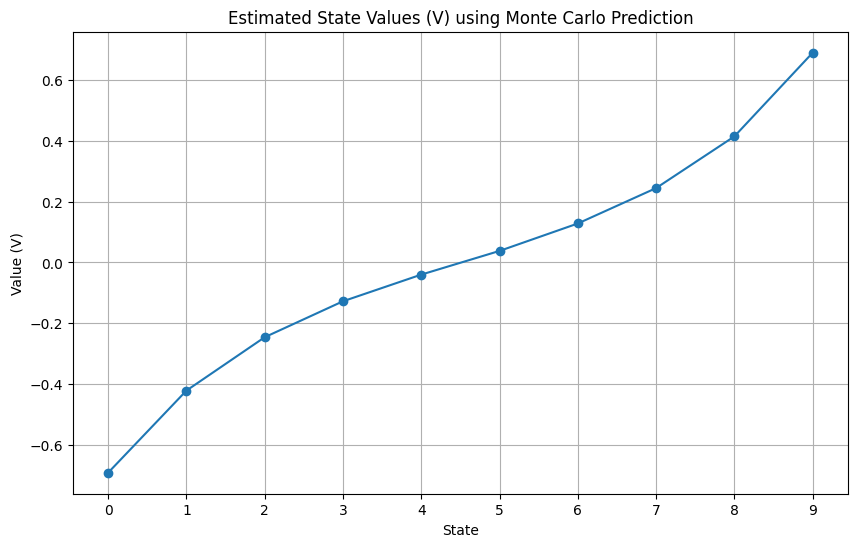

Estimated State Values:
State 0: -0.6910
State 1: -0.4211
State 2: -0.2456
State 3: -0.1275
State 4: -0.0399
State 5: 0.0380
State 6: 0.1281
State 7: 0.2444
State 8: 0.4144
State 9: 0.6893


In [6]:
plt.figure(figsize=(10, 6))
plt.plot(range(N_STATES), V, marker='o', linestyle='-')
plt.title('Estimated State Values (V) using Monte Carlo Prediction')
plt.xlabel('State')
plt.ylabel('Value (V)')
plt.xticks(range(N_STATES))
plt.grid(True)
plt.show()

print("Estimated State Values:")
for s, val in enumerate(V):
    print(f"State {s}: {val:.4f}")